# 06 · Finding target physicians and the recommendation

**Question:** if I were advising the maker of a GLP-1 or SGLT2 drug, **which prescribers should the field team see first?**

Approach, the way a pharma targeting study works:

1. **Segment prescribers** by what they prescribe for diabetes (k-means on their prescription mix).
2. **Model each prescriber's expected adoption** from things the brand can't change: specialty, state, patient volume, insulin use. I compare penalized (ridge) regression with a random forest.
3. **Headroom** = how far a prescriber sits below what similar prescribers do, times their diabetes volume. That's the number of claims a brand could realistically win by bringing them up to their peers.
4. Roll it up into the recommendation.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable when run from notebooks/

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.metrics import r2_score, mean_absolute_error
from src.config import PROCESSED, FIGURES, SERIES, MUTED, INK2, ADVANCED, style, update_results
style()

claims = pd.read_parquet(PROCESSED / "prescriber_claims.parquet")
states = pd.read_parquet(PROCESSED / "state_summary.parquet")
con = duckdb.connect(); con.register("claims", claims)

## 1. One row per prescriber

I keep prescribers with **at least 100 diabetes claims** in 2024. Below that, CMS privacy suppression (rows under 11 claims are hidden) distorts the mix too much to trust.

In [2]:
pres = con.sql('''
    SELECT Prscrbr_NPI AS npi, ANY_VALUE(Prscrbr_Type) AS specialty, ANY_VALUE(Prscrbr_State_Abrvtn) AS state,
           SUM(Tot_Clms) AS claims,
           SUM(CASE WHEN drug_class = 'Biguanide (metformin)' THEN Tot_Clms ELSE 0 END) / SUM(Tot_Clms) AS metformin,
           SUM(CASE WHEN drug_class IN ('Sulfonylurea', 'Meglitinide', 'Thiazolidinedione', 'Alpha-glucosidase inhibitor') THEN Tot_Clms ELSE 0 END) / SUM(Tot_Clms) AS older_orals,
           SUM(CASE WHEN drug_class = 'Insulin' THEN Tot_Clms ELSE 0 END) / SUM(Tot_Clms) AS insulin,
           SUM(CASE WHEN drug_class = 'DPP-4 inhibitor' THEN Tot_Clms ELSE 0 END) / SUM(Tot_Clms) AS dpp4,
           SUM(CASE WHEN drug_class = 'SGLT2 inhibitor' THEN Tot_Clms ELSE 0 END) / SUM(Tot_Clms) AS sglt2,
           SUM(CASE WHEN drug_class = 'GLP-1 / GIP-GLP-1 agonist' THEN Tot_Clms ELSE 0 END) / SUM(Tot_Clms) AS glp1,
           COUNT(DISTINCT drug_class) AS n_classes
    FROM claims GROUP BY 1 ORDER BY 1
''').df()                       # ORDER BY keeps row order (and so k-means and CV folds) identical across runs
print(f"{len(pres):,} prescribers with any diabetes claims")
pres = pres[pres.claims >= 100].copy()
pres["advanced"] = pres.sglt2 + pres.glp1
pres = pres.merge(states[["stateabbr", "diabetes_prev_pct", "obesity_prev_pct"]], left_on="state", right_on="stateabbr", how="left")
STATES = set("AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY".split())
pres = pres[pres.state.isin(STATES)]      # drops territories, military and foreign addresses
print(f"{len(pres):,} prescribers with 100+ claims kept; they write {pres.claims.sum()/claims.Tot_Clms.sum():.0%} of all diabetes claims")
pres.describe().T[["mean", "50%"]].round(3)

316,488 prescribers with any diabetes claims
184,034 prescribers with 100+ claims kept; they write 93% of all diabetes claims


,mean,50%
claims,524.114,344.000
metformin,0.358,0.362
older_orals,0.125,0.117
insulin,0.109,0.086
dpp4,0.045,0.025
sglt2,0.171,0.125
glp1,0.192,0.181
n_classes,5.194,5.000
advanced,0.363,0.335
diabetes_prev_pct,12.082,11.900


## 2. Prescriber segments (k-means on prescription mix)

Each prescriber is described by the share of their diabetes claims in six buckets. I try k = 2 to 8 and pick the k where the inertia curve bends, checked against whether the segments are easy to name. The drop in inertia flattens after k = 4, and four segments each have a clear identity.

In [3]:
MIX = ["metformin", "older_orals", "insulin", "dpp4", "sglt2", "glp1"]
Z = StandardScaler().fit_transform(pres[MIX])
inertia = {k: KMeans(k, n_init=10, random_state=0).fit(Z).inertia_ for k in range(2, 9)}
pd.Series(inertia).round(0)

2    869826.0
3    700502.0
4    582451.0
5    494129.0
6    436022.0
7    401780.0
8    380831.0
dtype: float64

In [4]:
K = 4
km = KMeans(K, n_init=20, random_state=0).fit(Z)
pres["cluster"] = km.labels_
centers = pres.groupby("cluster")[MIX + ["advanced", "claims"]].mean()
centers["prescribers"] = pres.cluster.value_counts()
centers.round(3)

,metformin,older_orals,insulin,dpp4,sglt2,glp1,advanced,claims,prescribers
cluster,,,,,,,,,
0,0.244,0.083,0.306,0.072,0.133,0.161,0.294,934.938,28637
1,0.363,0.069,0.073,0.025,0.148,0.322,0.470,408.166,64438
2,0.434,0.198,0.081,0.057,0.111,0.120,0.231,506.308,81198
3,0.022,0.008,0.003,0.007,0.928,0.033,0.961,232.386,9761


In [5]:
def name_cluster(r):
    if r.sglt2 >= 0.6:   return "SGLT2-only (heart / kidney)"
    if r.insulin >= 0.25: return "Insulin-heavy"
    if r.metformin + r.older_orals >= 0.55: return "Traditional orals"
    if r.advanced >= 0.4: return "Newer-drug adopters"
    return "Mixed"
centers["segment"] = centers.apply(name_cluster, axis=1)
assert centers.segment.nunique() == K, centers.segment       # names must be distinct
pres["segment"] = pres.cluster.map(centers.segment)
seg_tbl = (pres.groupby("segment")
             .agg(prescribers=("npi", "size"), claims=("claims", "sum"), advanced_pct=("advanced", "mean"),
                  metformin_pct=("metformin", "mean"), insulin_pct=("insulin", "mean"))
             .assign(claims_share_pct=lambda d: 100 * d.claims / d.claims.sum()))
seg_tbl[["advanced_pct", "metformin_pct", "insulin_pct"]] *= 100
seg_tbl = seg_tbl.round(1).sort_values("advanced_pct")
seg_tbl

,prescribers,claims,advanced_pct,metformin_pct,insulin_pct,claims_share_pct
segment,,,,,,
Traditional orals,81198,41111201.0,23.1,43.4,8.1,42.6
Insulin-heavy,28637,26773807.0,29.4,24.4,30.6,27.8
Newer-drug adopters,64438,26301390.0,47.0,36.3,7.3,27.3
SGLT2-only (heart / kidney),9761,2268318.0,96.1,2.2,0.3,2.4


In [6]:
spec_mix = (pd.crosstab(pres.specialty, pres.segment, normalize="index") * 100).round(0)
spec_mix.loc[pres.specialty.value_counts().index[:6]]

segment,Insulin-heavy,Newer-drug adopters,SGLT2-only (heart / kidney),Traditional orals
specialty,,,,
Family Practice,10.0,37.0,0.0,53.0
Nurse Practitioner,18.0,39.0,4.0,39.0
Internal Medicine,15.0,33.0,1.0,51.0
Physician Assistant,13.0,44.0,3.0,40.0
Endocrinology,75.0,22.0,0.0,2.0
Cardiology,1.0,13.0,78.0,8.0


## 3. Expected adoption: what would a similar prescriber do?

Target: each prescriber's GLP-1 + SGLT2 share. Features: specialty, state, log claim volume and insulin share. The state term absorbs local factors such as disease burden and payer mix (so the CDC prevalence figures aren't needed here, which keeps Kentucky and Pennsylvania in). Deliberately **no** brand-controllable inputs: the model describes the prescriber's situation, not their choices about new drugs.

I compare ridge regression (penalized, linear) and a random forest with 5-fold cross-validation, and use **out-of-fold** predictions so no prescriber is scored by a model that saw them.

In [7]:
pres["log_claims"] = np.log10(pres.claims)
top_spec = pres.specialty.value_counts().index[:15]
pres["specialty_g"] = pres.specialty.where(pres.specialty.isin(top_spec), "Other")
NUMF = ["log_claims", "insulin"]
CATF = ["specialty_g", "state"]
Xp, yp = pres[NUMF + CATF], pres.advanced.values
prep = ColumnTransformer([("num", StandardScaler(), NUMF),
                          ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATF)])
cands = {
    "Ridge regression": RidgeCV(alphas=np.logspace(-2, 3, 12)),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=40, max_features=0.5, n_jobs=-1, random_state=0),
}
kf = KFold(5, shuffle=True, random_state=1)
oof, perf = {}, []
for name, m in cands.items():
    pred = cross_val_predict(Pipeline([("prep", prep), ("m", m)]), Xp, yp, cv=kf, n_jobs=-1)
    oof[name] = pred
    perf.append({"model": name, "R2": r2_score(yp, pred), "MAE (share points)": 100 * mean_absolute_error(yp, pred)})
perf = pd.DataFrame(perf).round(3)
perf

,model,R2,MAE (share points)
0,Ridge regression,0.388,12.516
1,Random forest,0.418,12.205


In [8]:
best = perf.sort_values("R2", ascending=False).model.iloc[0]
pres["expected"] = np.clip(oof[best], 0, 1)
pres["gap"] = pres.expected - pres.advanced                # positive = below similar prescribers
pres["headroom_claims"] = (pres.gap.clip(lower=0) * pres.claims)
print(f"Using {best}. Prescribers below their expected share: {(pres.gap > 0).mean():.0%}")
total_head = pres.headroom_claims.sum()
srt = pres.sort_values("headroom_claims", ascending=False)
top20 = srt.headroom_claims.head(int(0.2 * len(srt))).sum() / total_head
top10k = srt.headroom_claims.head(10000).sum() / total_head
print(f"Total headroom: {total_head:,.0f} claims a year. Top 20% of prescribers hold {top20:.0%}; top 10,000 hold {top10k:.0%}")

Using Random forest. Prescribers below their expected share: 51%
Total headroom: 4,829,954 claims a year. Top 20% of prescribers hold 76%; top 10,000 hold 39%


**Concentration matters for a field team.** The random forest edges out ridge (R² 0.42 vs. 0.39), so its out-of-fold predictions set each prescriber's "expected" share. About half of prescribers sit below that line, and the **top 20% of prescribers hold about three-quarters of all headroom**. A rep team can cover most of the opportunity without calling on everyone.

One honest caveat: the model can only compare a prescriber with others who look similar on paper. A low share can be the right call for that doctor's patients (cost, kidney function, side effects), so headroom is where to **start a conversation**, not proof of under-treatment.

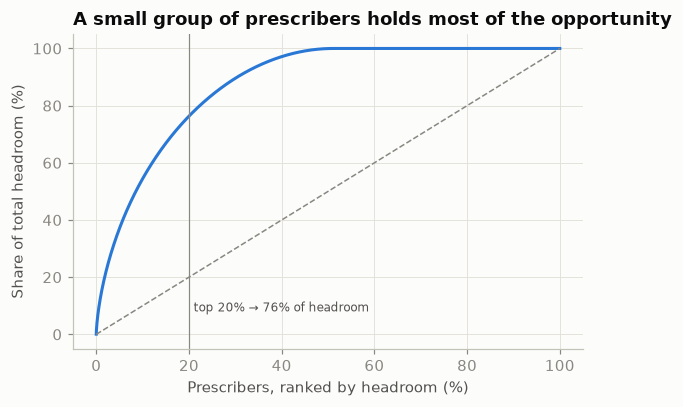

In [9]:
cum = srt.headroom_claims.cumsum() / total_head
xs = np.arange(1, len(cum) + 1) / len(cum) * 100
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(xs, cum.values * 100, color=SERIES[0], lw=2)
ax.plot([0, 100], [0, 100], color=MUTED, ls="--", lw=1)
ax.axvline(20, color=MUTED, lw=0.8); ax.text(21, 8, f"top 20% → {top20:.0%} of headroom", fontsize=8, color=INK2)
ax.set_xlabel("Prescribers, ranked by headroom (%)"); ax.set_ylabel("Share of total headroom (%)")
ax.set_title("A small group of prescribers holds most of the opportunity")
plt.tight_layout(); plt.savefig(FIGURES / "06_headroom_curve.png", dpi=160); plt.show()

## 4. Where the headroom is

In [10]:
by_spec = (pres.groupby("specialty")
             .agg(prescribers=("npi", "size"), claims=("claims", "sum"), actual=("advanced", "mean"),
                  expected=("expected", "mean"), headroom=("headroom_claims", "sum"))
             .assign(headroom_share_pct=lambda d: 100 * d.headroom / total_head,
                     headroom_per_prescriber=lambda d: d.headroom / d.prescribers)
             .sort_values("headroom", ascending=False))
by_spec[["actual", "expected"]] *= 100
by_spec.round(1).head(10)

,prescribers,claims,actual,expected,headroom,headroom_share_pct,headroom_per_prescriber
specialty,,,,,,,
Family Practice,59317,30785470.0,31.5,31.6,1479868.9,30.6,24.9
Internal Medicine,44232,27508056.0,31.9,31.9,1404090.9,29.1,31.7
Nurse Practitioner,44596,17292007.0,36.9,36.9,984104.8,20.4,22.1
Physician Assistant,14498,5625106.0,37.9,37.7,302338.9,6.3,20.9
Endocrinology,5457,8983221.0,42.2,41.9,289833.8,6.0,53.1
General Practice,2078,1318485.0,25.1,26.8,78363.8,1.6,37.7
Cardiology,4308,1176841.0,87.5,87.5,70533.8,1.5,16.4
Nephrology,2792,828508.0,84.5,84.1,48776.5,1.0,17.5
Geriatric Medicine,917,513406.0,24.9,28.6,35010.7,0.7,38.2


In [11]:
by_state = (pres.groupby("state")
              .agg(prescribers=("npi", "size"), headroom=("headroom_claims", "sum"), actual=("advanced", "mean"))
              .assign(headroom_share_pct=lambda d: 100 * d.headroom / total_head)
              .merge(states[["stateabbr", "statedesc", "diabetes_prev_pct", "quadrant", "adults_with_diabetes"]],
                     left_index=True, right_on="stateabbr")
              .sort_values("headroom", ascending=False))
by_state["actual"] *= 100
by_state.round(1).head(10)

,prescribers,headroom,actual,headroom_share_pct,stateabbr,statedesc,diabetes_prev_pct,quadrant,adults_with_diabetes
40,19437,534512.7,32.4,11.1,CA,California,11.7,"Low burden, low adoption",3571061.1
13,11906,400285.1,35.9,8.3,NY,New York,11.5,"Low burden, high adoption",1790170.0
1,12961,399457.5,33.7,8.3,FL,Florida,13.5,"High burden, low adoption",2460085.9
24,12998,356425.3,39.1,7.4,TX,Texas,12.7,"High burden, high adoption",2922262.4
14,7290,202879.1,35.1,4.2,OH,Ohio,13.2,"High burden, low adoption",1220001.9
34,6568,192714.7,33.8,4.0,IL,Illinois,11.7,"Low burden, low adoption",1146933.9
11,6496,152994.9,40.3,3.2,NC,North Carolina,12.0,"High burden, high adoption",1022497.4
2,5085,149522.9,41.0,3.1,GA,Georgia,13.3,"High burden, high adoption",1128497.7
12,4506,147685.0,32.1,3.1,NJ,New Jersey,10.9,"Low burden, low adoption",794658.5
5,6656,146284.5,37.6,3.0,MI,Michigan,11.9,"High burden, high adoption",946933.2


In [12]:
by_seg = (pres.groupby("segment").agg(prescribers=("npi", "size"), headroom=("headroom_claims", "sum"))
            .assign(headroom_share_pct=lambda d: (100 * d.headroom / total_head).round(1))
            .sort_values("headroom", ascending=False))
by_seg

,prescribers,headroom,headroom_share_pct
segment,,,
Traditional orals,81198,3.741877e+06,77.5
Insulin-heavy,28637,8.809450e+05,18.2
Newer-drug adopters,64438,1.807966e+05,3.7
SGLT2-only (heart / kidney),9761,2.633562e+04,0.5


## 5. Recommendation

Putting the four notebooks together:

1. **Who the patients are.** In the 1999–2008 hospital data, the diabetic patients most likely to be back within 30 days are those already cycling through the hospital and those discharged to a care facility (20–21% readmitted, more than twice the average). Close to 6 in 10 diabetic patients had a heart diagnosis, the group today's guidelines steer toward GLP-1 and SGLT2 drugs (notebooks 03–04).
2. **The market has moved, unevenly.** GLP-1 and SGLT2 drugs now take **76%** of Medicare diabetes spending but only **33%** of claims (notebook 05). Family practice, internal medicine and nurse practitioners write 77% of diabetes claims and trail endocrinology on the newer classes.
3. **Where to focus.** Of 184,000 prescribers with 100+ diabetes claims, the top 20% by headroom hold about three-quarters of it. It's concentrated in **family practice, internal medicine and nurse practitioners** (together ~80%) and in the **"traditional orals" segment** (metformin and sulfonylurea-heavy prescribers, ~78%). By state, California, Florida, New York and Texas hold the most. **Florida and Ohio** are both high-burden, low-adoption *and* top-five for headroom, which makes them the first two markets to test a program in.

**What I'd recommend to a GLP-1 / SGLT2 brand:** start with high-headroom primary care prescribers in the traditional-orals segment, beginning in Florida and Ohio. Lead with heart and kidney outcomes, since that's the patient profile with the highest readmission burden. Measure success by the change in those prescribers' GLP-1 + SGLT2 share against matched prescribers who weren't called on.

**Limitations.** Medicare Part D covers mostly patients 65+. CMS hides rows under 11 claims. The hospital data is 1999–2008 and observational, so it shows correlations, not causes. **Next steps:** add commercial claims (e.g. IQVIA or Symphony), build a physician referral network from shared patients, and run a survival analysis of time-to-adoption once a new drug launches.

The numbers behind each point are saved to `docs/results.json` for the presentation.

In [13]:
seg_sizes = pres.segment.value_counts().to_dict()
update_results("targeting", {
    "prescribers_kept": int(len(pres)),
    "claims_covered_pct": round(100 * pres.claims.sum() / claims.Tot_Clms.sum(), 1),
    "segments": seg_tbl.reset_index().to_dict("records"),
    "segment_headroom": by_seg.reset_index().to_dict("records"),
    "model_perf": perf.to_dict("records"), "best_model": best,
    "total_headroom": round(total_head), "top20_share": round(100 * top20, 1), "top10k_share": round(100 * top10k, 1),
    "below_expected_pct": round(100 * (pres.gap > 0).mean(), 1),
    "by_specialty": by_spec.reset_index().head(10).round(3).to_dict("records"),
    "by_state": by_state.head(12).round(3).to_dict("records"),
    "curve": [{"pct_prescribers": float(x), "pct_headroom": float(y)} for x, y in
              zip(np.linspace(0, 100, 51), np.interp(np.linspace(0, 100, 51), np.r_[0, xs], np.r_[0, cum.values * 100]))],
})
print("saved")

saved
